In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

VIDEO = "Volleyball.mp4"
OUTPUT = "volleyball_tracked.mp4"

team_colours = {"BRA": (0, 220, 255), "ARG": (255, 140, 0)}

video = cv2.VideoCapture(VIDEO)
if not video.isOpened():
    raise RuntimeError("Could not open Volleyball.mp4.")

fps = video.get(cv2.CAP_PROP_FPS)
width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
video.release()

print(f"Video: {width}x{height} at {fps:.0f} FPS")


Video: 1280x720 at 30 FPS


Frames decoded: 2401 (80.0 seconds)


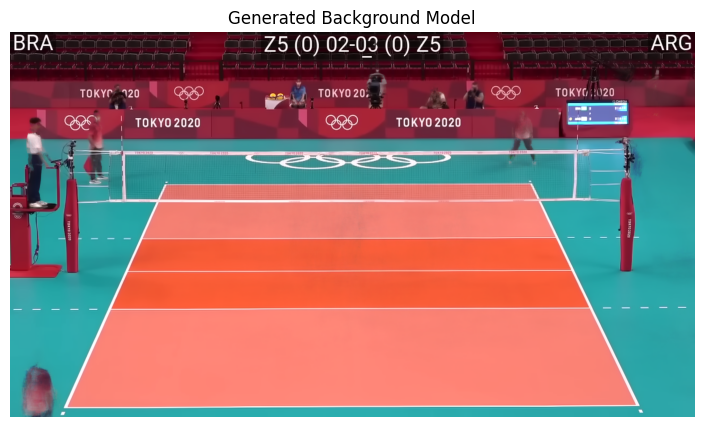

In [2]:
video = cv2.VideoCapture(str(VIDEO))
sampled_frames = []
frame_count = 0

while True:
    success, frame = video.read()
    if not success:
        break

    if frame_count % 12 == 0:
        sampled_frames.append(frame)

    frame_count += 1

video.release()

if not sampled_frames:
    raise RuntimeError("No frames could be read from the video.")

background = np.median(np.stack(sampled_frames), axis=0).astype(np.uint8)
del sampled_frames

background_blur = cv2.GaussianBlur(background, (5, 5), 0).astype(np.int16)
print(f"Frames decoded: {frame_count} ({frame_count / fps:.1f} seconds)")
plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(background, cv2.COLOR_BGR2RGB))
plt.title("Generated Background Model")
plt.axis("off")
plt.show()


In [3]:
IGNORE = np.zeros((height, width), np.uint8)
ignore_areas = [
    (0, 0, 100, 45),
    (460, 0, 820, 50),
    (1190, 0, 1280, 45),
    (1030, 120, 1170, 180)
]

for x1, y1, x2, y2 in ignore_areas:
    IGNORE[y1:y2, x1:x2] = 255

COURT = np.array([
    [255, 150], [1015, 150], [1215, 722], [70, 722]
], np.int32)

court_mask = np.zeros((height, width), np.uint8)
cv2.fillPoly(court_mask, [COURT], 255)

KERNEL_SMALL = np.ones((3, 3), np.uint8)
KERNEL_BRAZIL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 15))
KERNEL_ARGENTINA = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 41))


def get_foreground(frame, threshold):
    """Return pixels that differ sufficiently from the background."""
    blurred = cv2.GaussianBlur(frame, (5, 5), 0).astype(np.int16)
    difference = np.abs(blurred - background_blur)
    return (difference.max(axis=2) > threshold).astype(np.uint8) * 255


def detect_ball(frame):
    """Find orange, roughly circular objects that may be the ball."""
    mask = get_foreground(frame, 35)
    mask[IGNORE > 0] = 0
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, KERNEL_SMALL)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, KERNEL_SMALL)

    count, labels, stats, centers = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    candidates = []

    for i in range(1, count):
        x, y, w, h, area = stats[i]

        valid_shape = (
            100 <= area <= 900
            and 12 <= w <= 42
            and 12 <= h <= 42
            and 0.6 <= w / h <= 1.7
            and area / (w * h) > 0.45
        )
        if not valid_shape:
            continue

        region = hsv[y:y + h, x:x + w]
        pixels = region[labels[y:y + h, x:x + w] == i]
        hue, saturation, value = np.median(pixels, axis=0)

        if 4 <= hue <= 26 and saturation >= 85 and value >= 150:
            candidates.append((
                centers[i][0], centers[i][1],
                area, w, h, hue, saturation, value
            ))

    return candidates


def detect_players(frame):
    """Find Brazil's yellow and Argentina's blue player blobs."""
    foreground = get_foreground(frame, 40) & court_mask
    hue, saturation, value = cv2.split(
        cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    )

    yellow_mask = (
        (hue >= 10) & (hue <= 24)
        & (saturation >= 130) & (value >= 140)
    ).astype(np.uint8) * 255
    blue_mask = (
        (hue >= 100) & (hue <= 128)
        & (saturation >= 30) & (value >= 40) & (value <= 190)
    ).astype(np.uint8) * 255

    yellow_mask &= foreground
    blue_mask &= foreground

    teams = {}
    team_settings = [
        ("BRA", yellow_mask, KERNEL_BRAZIL, 250),
        ("ARG", blue_mask, KERNEL_ARGENTINA, 500)
    ]

    for team, mask, kernel, minimum_area in team_settings:
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, KERNEL_SMALL)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

        count, _, stats, _ = cv2.connectedComponentsWithStats(mask)

        team_boxes = []

        for i in range(1, count):
            if stats[i][4] >= minimum_area:
                box = tuple(int(value) for value in stats[i])
                team_boxes.append(box)

        teams[team] = team_boxes

    return teams


Processed 500 frames...
Processed 1000 frames...
Processed 1500 frames...
Processed 2000 frames...
Analysed 2401 frames.
Average ball candidates per frame: 0.79


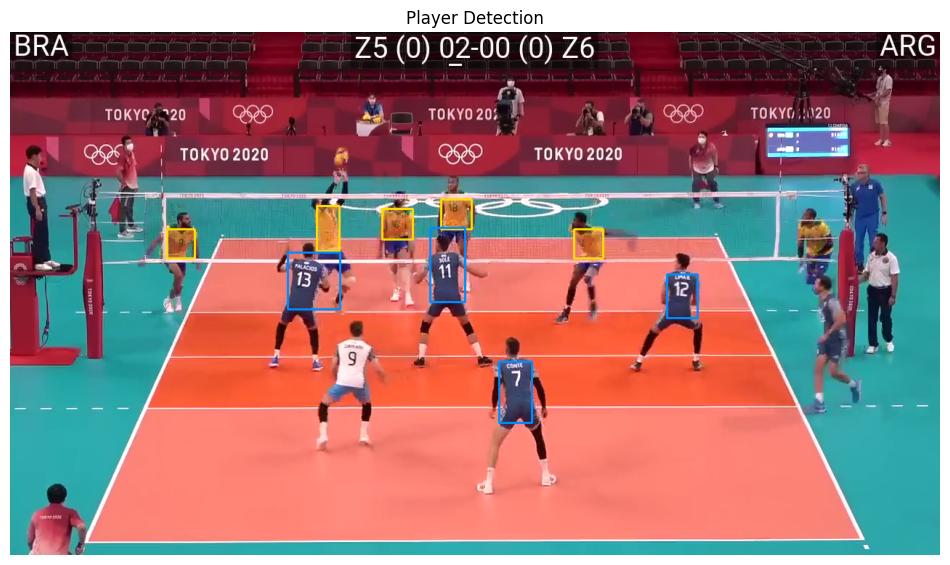

In [4]:
ball_candidates = []
player_blobs = []

video = cv2.VideoCapture(str(VIDEO))
frame_number = 0

while True:
    success, frame = video.read()
    if not success:
        break

    ball_candidates.append(detect_ball(frame))
    player_blobs.append(detect_players(frame))
    frame_number += 1

    if frame_number % 500 == 0:
        print(f"Processed {frame_number} frames...")

video.release()

total_frames = len(ball_candidates)
print(f"Analysed {total_frames} frames.")

candidate_total = 0
for candidates in ball_candidates:
    candidate_total += len(candidates)

average_candidates = candidate_total / total_frames
print("Average ball candidates per frame:", round(average_candidates, 2))

sample_frame = total_frames // 3
video = cv2.VideoCapture(str(VIDEO))
video.set(cv2.CAP_PROP_POS_FRAMES, sample_frame)
success, frame = video.read()
video.release()

if success:
    for team, colour in team_colours.items():
        for x, y, box_width, box_height, area in player_blobs[sample_frame][team]:
            cv2.rectangle(frame, (x, y), (x + box_width, y + box_height), colour, 2)

    plt.figure(figsize=(12, 7))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title("Player Detection")
    plt.axis("off")
    plt.show()


Tracklets found: 130
Ball tracks kept: 44
Ball detected in 590/2401 frames (24.6%).
Interpolated positions: 140


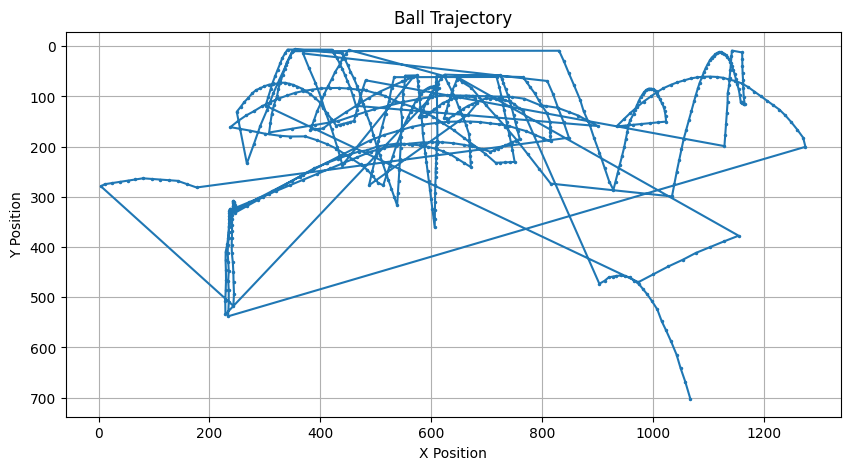

In [5]:
def extend_ball_track(start_frame, start_index, max_missing=4):
    """Follow a ball candidate through later frames."""
    path = [(start_frame, start_index)]
    x, y = ball_candidates[start_frame][start_index][:2]

    velocity_x = velocity_y = 0.0
    missing = 0
    hits = 1
    frame_number = start_frame

    while frame_number + 1 < total_frames:
        frame_number += 1
        predicted_x = x + velocity_x
        predicted_y = y + velocity_y

        gate = (
            25 + 0.5 * np.hypot(velocity_x, velocity_y)
            if hits > 1 else 70
        )

        best_index = None
        best_distance = float("inf")

        for index, candidate in enumerate(ball_candidates[frame_number]):
            distance = np.hypot(
                candidate[0] - predicted_x,
                candidate[1] - predicted_y
            )

            if distance < gate and distance < best_distance:
                best_distance = distance
                best_index = index

        if best_index is None:
            missing += 1
            if missing > max_missing:
                break

            x, y = predicted_x, predicted_y
            continue

        candidate = ball_candidates[frame_number][best_index]
        steps = missing + 1

        new_velocity_x = (candidate[0] - x) / steps
        new_velocity_y = (candidate[1] - y) / steps

        if hits == 1:
            velocity_x, velocity_y = new_velocity_x, new_velocity_y
        else:
            velocity_x = 0.5 * velocity_x + 0.5 * new_velocity_x
            velocity_y = 0.5 * velocity_y + 0.5 * new_velocity_y

        x, y = candidate[:2]
        missing = 0
        hits += 1
        path.append((frame_number, best_index))

    return path


used_candidates = set()
tracklets = []

for frame_number, candidates in enumerate(ball_candidates):
    for candidate_index in range(len(candidates)):
        if (frame_number, candidate_index) in used_candidates:
            continue

        path = extend_ball_track(frame_number, candidate_index)
        used_candidates.update(path)

        if len(path) < 4:
            continue

        points_list = []
        features_list = []

        for track_frame, track_candidate_index in path:
            candidate = ball_candidates[track_frame][track_candidate_index]
            points_list.append(candidate[:2])
            features_list.append(candidate[2:])

        points = np.array(points_list)
        features = np.array(features_list)

        duration = max(1, path[-1][0] - path[0][0])

        tracklets.append({
            "path": path,
            "points": points,
            "start": path[0][0],
            "end": path[-1][0],
            "speed": np.hypot(*(points[-1] - points[0])) / duration,
            "area": np.median(features[:, 0]),
            "hue": np.median(features[:, 3]),
            "saturation": np.median(features[:, 4])
        })

ball_tracks = []

for track in tracklets:
    if (track["speed"] >= 4 and track["hue"] >= 10
            and track["saturation"] >= 100 and track["area"] <= 650):
        ball_tracks.append(track)

ball_positions = {}

for track in ball_tracks:
    for (frame_number, _), (x, y) in zip(track["path"], track["points"]):
        ball_positions[frame_number] = (x, y, "detected")


def interpolate_ball_gap(start, end):
    """Fill a short gap between two known ball positions."""
    x1, y1, _ = ball_positions[start]
    x2, y2, _ = ball_positions[end]

    for frame_number in range(start + 1, end):
        fraction = (frame_number - start) / (end - start)
        x = x1 + fraction * (x2 - x1)
        y = y1 + fraction * (y2 - y1)
        ball_positions[frame_number] = (x, y, "interpolated")


detected_frames = sorted(ball_positions)

for start, end in zip(detected_frames[:-1], detected_frames[1:]):
    gap = end - start

    if 1 < gap <= 10:
        x1, y1, _ = ball_positions[start]
        x2, y2, _ = ball_positions[end]
        distance = np.hypot(x2 - x1, y2 - y1)

        if distance <= 40 + 45 * gap:
            interpolate_ball_gap(start, end)

detected_count = sum(
    position[2] == "detected" for position in ball_positions.values()
)
interpolated_count = len(ball_positions) - detected_count

print(f"Tracklets found: {len(tracklets)}")
print(f"Ball tracks kept: {len(ball_tracks)}")
print(
    f"Ball detected in {detected_count}/{total_frames} frames "
    f"({100 * detected_count / total_frames:.1f}%)."
)
print(f"Interpolated positions: {interpolated_count}")
positions = []

for frame_number in sorted(ball_positions):
    positions.append(ball_positions[frame_number])

x = []
y = []

for position in positions:
    x.append(position[0])
    y.append(position[1])

plt.figure(figsize=(10, 5))
plt.plot(x, y, marker=".", markersize=3)
plt.gca().invert_yaxis()
plt.title("Ball Trajectory")
plt.xlabel("X Position")
plt.ylabel("Y Position")
plt.grid()
plt.show()


Estimated players on court — Brazil: 6
Estimated players on court — Argentina: 5
BRA: estimated count appears in 41% of frames; within ±1 in 86%.
ARG: estimated count appears in 25% of frames; within ±1 in 61%.


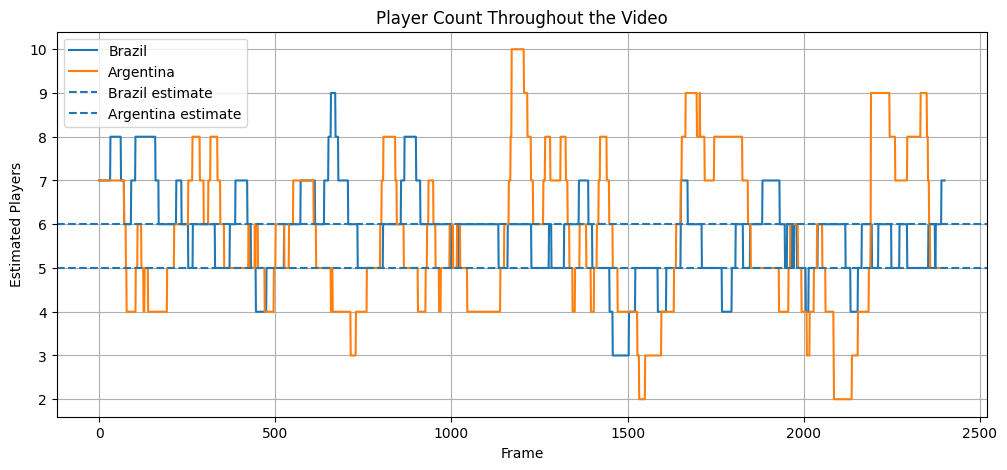

In [6]:
DEPTH_BINS = np.array([150, 250, 330, 400, 470, 540, 620, 730])


def calibrate_team(team):
    """Estimate one-player blob area at different court depths."""
    maximum_width = 48 if team == "BRA" else 56

    measurements_list = []

    for frame in player_blobs:
        for box in frame[team]:
            if box[2] <= maximum_width and 1.0 <= box[3] / box[2] <= 3.8:
                center_y = box[1] + box[3] / 2
                measurements_list.append((center_y, box[4]))

    measurements = np.array(measurements_list)

    average_depth = []
    typical_area = []

    for lower, upper in zip(DEPTH_BINS[:-1], DEPTH_BINS[1:]):
        group = measurements[
            (measurements[:, 0] >= lower)
            & (measurements[:, 0] < upper)
        ]

        if len(group) > 40:
            average_depth.append(group[:, 0].mean())
            typical_area.append(np.median(group[:, 1]))

    return np.array(average_depth), np.array(typical_area)


calibration = {}

for team in ("BRA", "ARG"):
    calibration[team] = calibrate_team(team)


def count_blob(team, box):
    """Estimate how many players are represented by one blob."""
    depths, typical_areas = calibration[team]
    center_y = box[1] + box[3] / 2
    one_player_area = np.interp(center_y, depths, typical_areas)

    return int(np.clip(round(box[4] / one_player_area), 1, 4))


raw_counts = {}

for team in ("BRA", "ARG"):
    team_counts = []

    for frame in player_blobs:
        frame_count = 0

        for box in frame[team]:
            frame_count += count_blob(team, box)

        team_counts.append(frame_count)

    raw_counts[team] = np.array(team_counts)


def smooth_counts(counts, window=31):
    """Apply a running median to reduce sudden counting changes."""
    padding = window // 2
    padded = np.pad(counts, (padding, padding), mode="edge")

    smoothed = []

    for i in range(len(counts)):
        smoothed.append(np.median(padded[i:i + window]))

    return np.array(smoothed).astype(int)


smoothed_counts = {}

for team, counts in raw_counts.items():
    smoothed_counts[team] = smooth_counts(counts)

brazil_count = int(np.median(smoothed_counts["BRA"]))
argentina_count = int(np.median(smoothed_counts["ARG"]))

print(f"Estimated players on court — Brazil: {brazil_count}")
print(f"Estimated players on court — Argentina: {argentina_count}")

for team, estimate in (("BRA", brazil_count), ("ARG", argentina_count)):
    counts = smoothed_counts[team]
    exact = 100 * np.mean(counts == estimate)
    within_one = 100 * np.mean(np.abs(counts - estimate) <= 1)

    print(
        f"{team}: estimated count appears in {exact:.0f}% of frames; "
        f"within ±1 in {within_one:.0f}%."
    )
plt.figure(figsize=(12, 5))

plt.plot(smoothed_counts["BRA"], label="Brazil")
plt.plot(smoothed_counts["ARG"], label="Argentina")

plt.axhline(brazil_count, linestyle="--", label="Brazil estimate")
plt.axhline(argentina_count, linestyle="--", label="Argentina estimate")

plt.title("Player Count Throughout the Video")
plt.xlabel("Frame")
plt.ylabel("Estimated Players")
plt.legend()
plt.grid()
plt.show()


In [7]:
video = cv2.VideoCapture(str(VIDEO))
writer = cv2.VideoWriter(
    OUTPUT,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

if not writer.isOpened():
    video.release()
    raise RuntimeError("Could not create the output video.")

frame_number = 0

while True:
    success, frame = video.read()
    if not success or frame_number >= total_frames:
        break

    for team, colour in team_colours.items():
        for x, y, box_width, box_height, _ in player_blobs[frame_number][team]:
            cv2.rectangle(
                frame,
                (x, y),
                (x + box_width, y + box_height),
                colour,
                1
            )

    if frame_number in ball_positions:
        x, y, source = ball_positions[frame_number]
        colour = (0, 255, 0) if source == "detected" else (0, 255, 255)
        cv2.circle(frame, (int(x), int(y)), 22, colour, 3)

    cv2.rectangle(frame, (0, 650), (430, 720), (0, 0, 0), -1)

    ball_status = (
        "tracked" if frame_number in ball_positions else "not visible"
    )
    cv2.putText(
        frame, f"Ball: {ball_status}", (10, 676),
        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2
    )
    cv2.putText(
        frame,
        f"Brazil: {smoothed_counts['BRA'][frame_number]}   "
        f"Argentina: {smoothed_counts['ARG'][frame_number]}",
        (10, 705),
        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2
    )

    writer.write(frame)
    frame_number += 1

video.release()
writer.release()

print(f"Saved annotated video: {OUTPUT}")


Saved annotated video: volleyball_tracked.mp4
